# Name : Luqman Khan
# SID : S2024266054

# Task 1 — CNN from Scratch on MNIST

**Step 1: Import libraries**

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


Step 2: Load MNIST dataset

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()


print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", x_test.shape)
print("Testing Labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


**Step 3: Reshape and normalize images**

In [3]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)


x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


**Step 4: Visualize two images from each class**

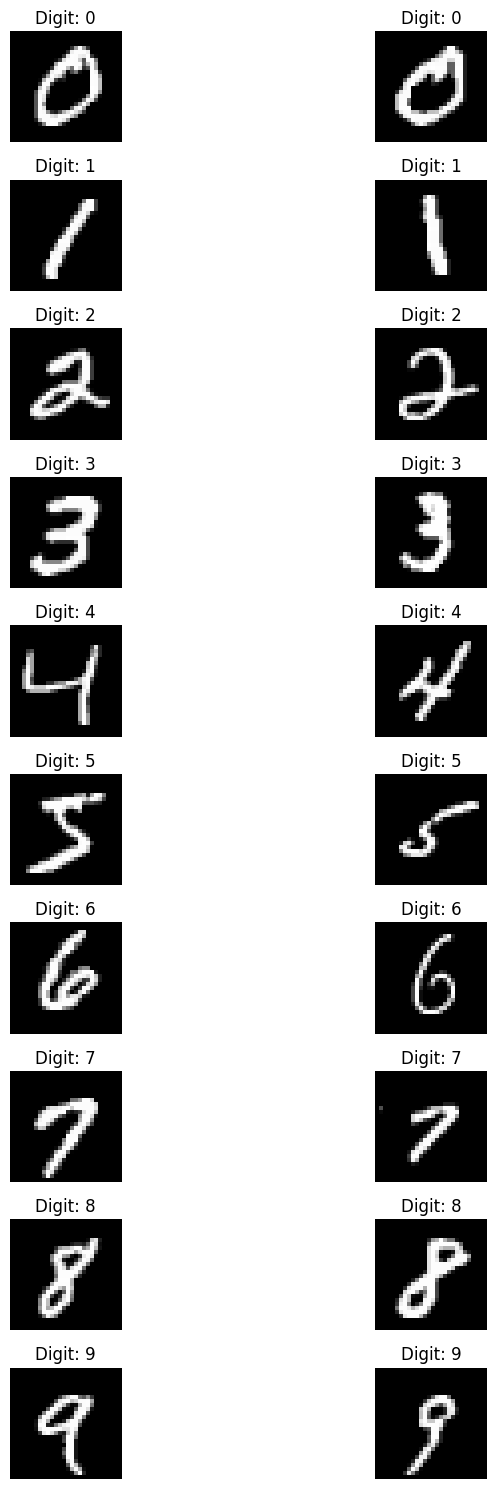

In [4]:
plt.figure(figsize=(10, 15))

for digit in range(10):


    indices = np.where(y_train == digit)[0][:2]

    for j, index in enumerate(indices):

        plt.subplot(10, 2, digit * 2 + j + 1)

        plt.imshow(x_train[index].squeeze(), cmap="gray")

        plt.title(f"Digit: {digit}")

        plt.axis("off")

plt.tight_layout()
plt.show()

**Step 5: Build CNN architecture**

Required architecture:
1. Conv2D — 64 filters, 3×3, ReLU
2. MaxPooling2D — 2×2
3. Conv2D — 64 filters, 3×3, ReLU
4. MaxPooling2D — 2×2
5. Flatten
6. Dense — 128 neurons, ReLU
7. Dense — 10 neurons, Softmax

In [5]:
model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),


    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),


    layers.Flatten(),


    layers.Dense(128, activation="relu"),

    layers.Dense(10, activation="softmax")

])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


**Step 6: Compile the model**

In [6]:
model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model Compiled Successfully!")

Model Compiled Successfully!


**Step 7: Calculate output shapes and parameters by hand**

In [7]:
print("HAND CALCULATION OF CNN PARAMETERS")


conv1 = (3 * 3 * 1 + 1) * 64

conv2 = (3 * 3 * 64 + 1) * 64

dense1 = (1600 * 128) + 128

dense2 = (128 * 10) + 10

total_parameters = conv1 + conv2 + dense1 + dense2

print("Conv2D Layer 1:", conv1)
print("Conv2D Layer 2:", conv2)
print("Dense Layer 1:", dense1)
print("Output Layer:", dense2)


print("Total Parameters:", total_parameters)

HAND CALCULATION OF CNN PARAMETERS
Conv2D Layer 1: 640
Conv2D Layer 2: 36928
Dense Layer 1: 204928
Output Layer: 1290
Total Parameters: 243786


**Step 8: Verify architecture using model.summary()**

In [8]:
model.summary()

print("Total Trainable Parameters:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,786 (952.29 KB)

 Trainable params: 243,786 (952.29 KB)

 Non-trainable params: 0 (0.00 B)

Total Trainable Parameters: 243786


**Step 9: Train the CNN model**
Requirements:
- Optimizer: Adam
- Loss: Sparse categorical cross-entropy
- Epochs: 5
- Validation split: 0.2

In [9]:
history = model.fit(

    x_train,
    y_train,

    epochs=5,

    batch_size=128,

    validation_split=0.2,

    verbose=1

)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 71s 186ms/step - accuracy: 0.9319 - loss: 0.2322 - val_accuracy: 0.9779 - val_loss: 0.0716
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 86s 196ms/step - accuracy: 0.9811 - loss: 0.0614 - val_accuracy: 0.9842 - val_loss: 0.0512
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 68s 181ms/step - accuracy: 0.9873 - loss: 0.0416 - val_accuracy: 0.9879 - val_loss: 0.0419
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 184ms/step - accuracy: 0.9903 - loss: 0.0316 - val_accuracy: 0.9900 - val_loss: 0.0402
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 80s 180ms/step - accuracy: 0.9923 - loss: 0.0255 - val_accuracy: 0.9892 - val_loss: 0.0412


**Step 10: Evaluate model performance**

In [10]:

train_loss, train_accuracy = model.evaluate(
    x_train, y_train, verbose=0
)


test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

validation_accuracy = history.history["val_accuracy"][-1]

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")

print("Validation Accuracy:", round(validation_accuracy * 100, 2), "%")

print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print("Test Loss:", round(test_loss, 4))

Training Accuracy: 99.38 %
Validation Accuracy: 98.92 %
Testing Accuracy: 98.93 %
Test Loss: 0.0338


**Step 11: Plot accuracy and loss curves**

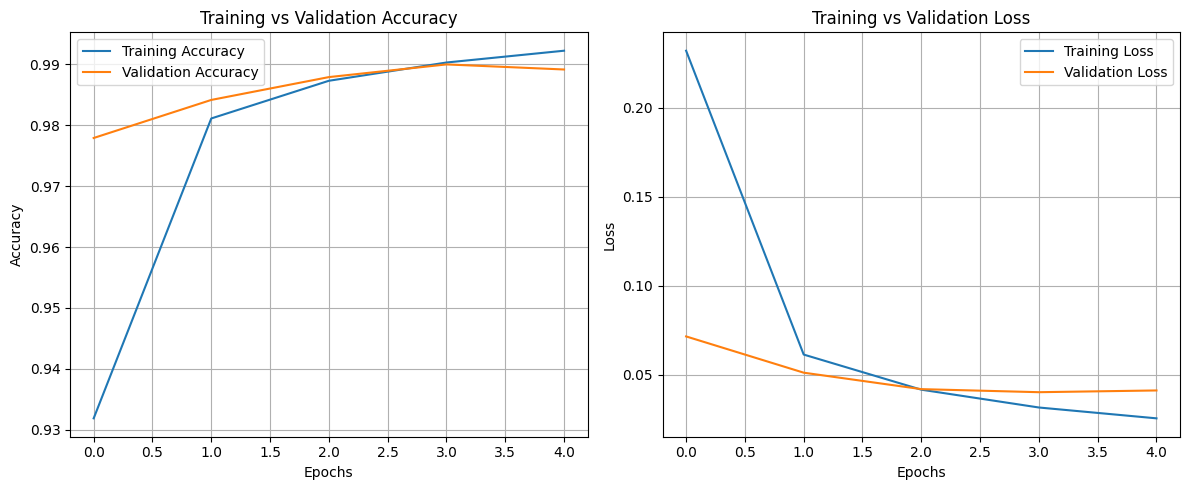

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

**Step 12: Display 10 misclassified test images**

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


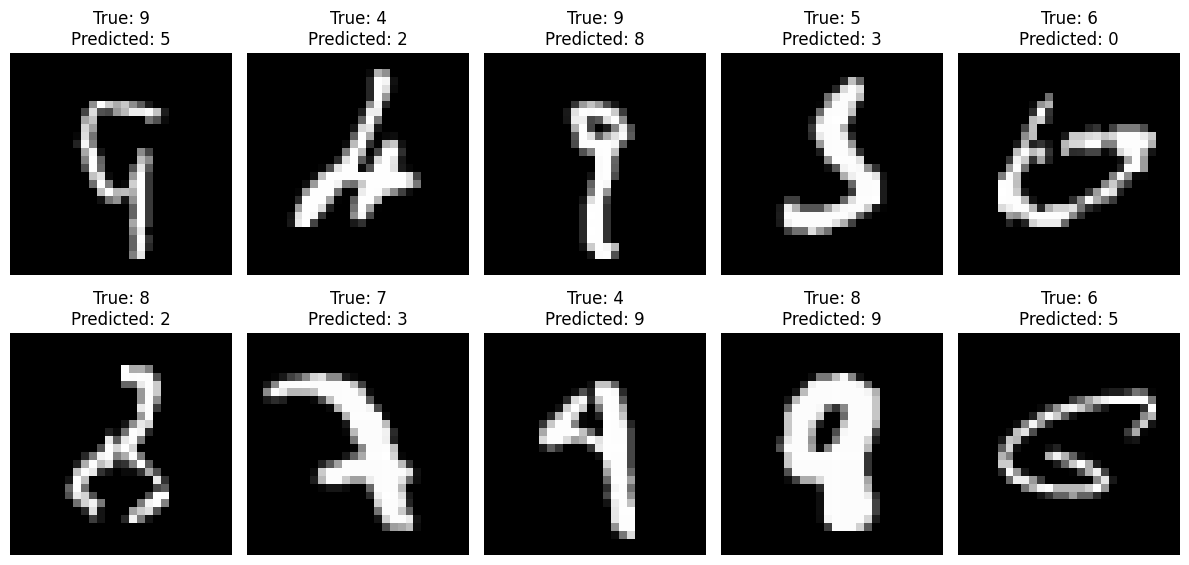

In [12]:
predictions = model.predict(x_test)

predicted_labels = np.argmax(predictions, axis=1)

wrong_indices = np.where(predicted_labels != y_test)[0]

wrong_indices = wrong_indices[:10]

plt.figure(figsize=(12, 6))

for i, index in enumerate(wrong_indices):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[index].squeeze(), cmap="gray")

    plt.title(
        f"True: {y_test[index]}\nPredicted: {predicted_labels[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

**Step 13: Visualize 64 learned filters**

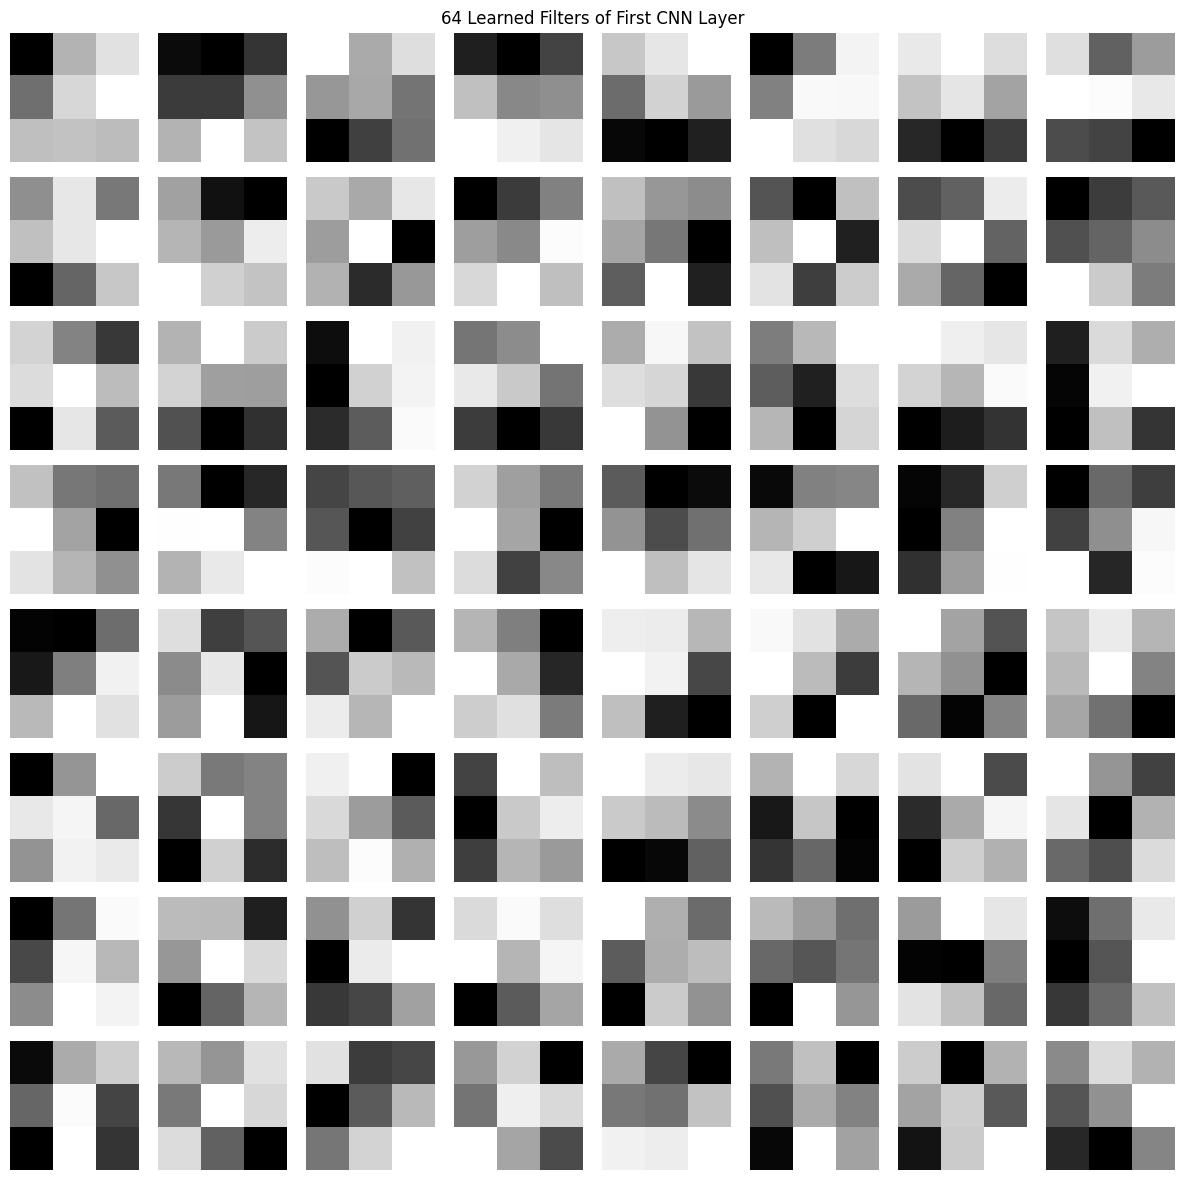

In [13]:

filters, biases = model.layers[0].get_weights()

plt.figure(figsize=(12, 12))

for i in range(64):

    plt.subplot(8, 8, i + 1)

    plt.imshow(filters[:, :, 0, i], cmap="gray")

    plt.axis("off")

plt.suptitle("64 Learned Filters of First CNN Layer")

plt.tight_layout()
plt.show()

**Step 14: Visualize feature maps**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


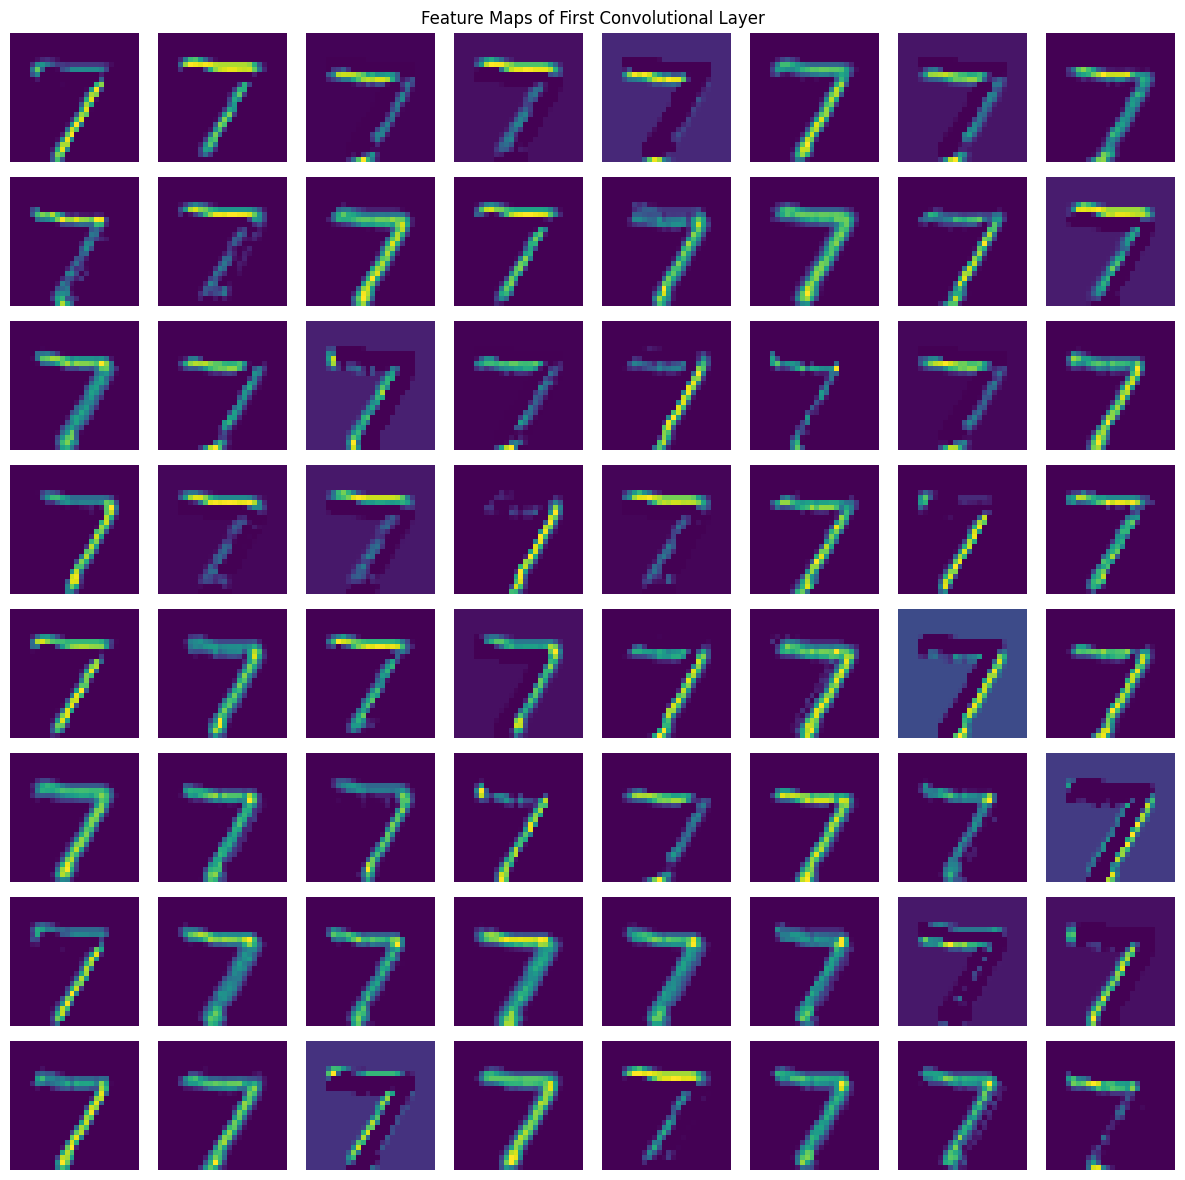

In [17]:

# Select one sample image
sample_image = x_test[0:1]

# Build the model first
_ = model(sample_image, training=False)

# Create feature extraction model
feature_model = keras.Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)

# Extract feature maps
feature_maps = feature_model.predict(sample_image)

# Display feature maps
plt.figure(figsize=(12, 12))

num_features = min(64, feature_maps.shape[-1])

for i in range(num_features):
    plt.subplot(8, 8, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.axis("off")

plt.suptitle("Feature Maps of First Convolutional Layer")
plt.tight_layout()
plt.show()
